# Tendência própria: avaliação por simulação (lote 1)

**Ficha:** [`docs/modelagens/tendencia.md`](../../docs/modelagens/tendencia.md) · **ADR:** 0040 (proposto) · **Status:** em avaliação

## 1. Pergunta

A Tendência (ver `CONTEXT.md`) substituirá o Comparativo vs. mediana. Para cada governador, queremos dizer **Subindo, Caindo,
Estável ou Dados insuficientes** a partir da série **bruta por data de publicação**, sem comparar com os demais perfis.

Qual método sustenta esse contrato sem inventar seta (falso alarme), sem perder tendência real (poder) e com intervalo de
confiança honesto (calibração)?

## 2. Contrato dos quatro estados (parâmetros a calibrar)

- **Dados insuficientes**: menos de `MIN_PUBLICACOES` publicações ou de `MIN_DIAS_COM_PUBLICACAO` dias distintos. Nenhuma seta.
- **Subindo / Caindo**: o intervalo de confiança da variação no período exclui zero **e** a variação estimada passa de
  `MIN_EFEITO` (5%) do nível do próprio governador.
- **Estável**: todo o resto.

## 3. Por que simulação primeiro

A Silver do piloto tem ~17 reels por perfil espalhados em 21 meses (teto de 30 itens), o que não permite dizer qual método é
melhor. Aqui geramos séries com **verdade conhecida** e características do dado real (publicação irregular e em rajadas, ruído
grande, posts virais, mudança de mix de formatos). O dado real de 90 dias (Coleta #256) entra depois, em *backtest*.

**Limite desta avaliação:** a simulação mede o comportamento dos métodos sob as premissas do gerador. Ela não prova que o
Instagram real se comporta assim. Por isso a decisão final só sai depois do backtest com dado real.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

PERIODO_DIAS = 90
MIN_PUBLICACOES = 10
MIN_DIAS_COM_PUBLICACAO = 8
MIN_EFEITO = 0.05
NIVEL_CONF = 0.95
N_GOVERNADORES = 26
REPS = 20
SEED = 20261011

EFEITOS = np.array([-0.30, -0.15, 0.0, 0.15, 0.30])
PROBS = np.array([0.10, 0.15, 0.50, 0.15, 0.10])
N_POSTS = [12, 40, 100, 250]
CENARIOS = ["base", "viral", "mix"]

## 4. Gerador de séries sintéticas

Cada governador recebe um nível próprio (log-normal) e uma variação verdadeira no período (`efeito`, em %). O valor de cada post
é `nível * (1 + efeito)^t * ruído`, com `t` em fração do período (0 a 1).

Três cenários:

- **base**: ruído moderado, 1% de posts virais (×5).
- **viral**: ruído maior, 4% de posts virais (×8). Testa robustez a outliers.
- **mix**: o formato B rende ~3× o formato A e sua participação sobe de 20% para 60% ao longo do período, **sem efeito real
  dentro de cada formato**. Testa se o método confunde mudança de mix com tendência.

Publicação irregular: os dias são sorteados com pesos gama (rajadas e buracos), não uniformes.

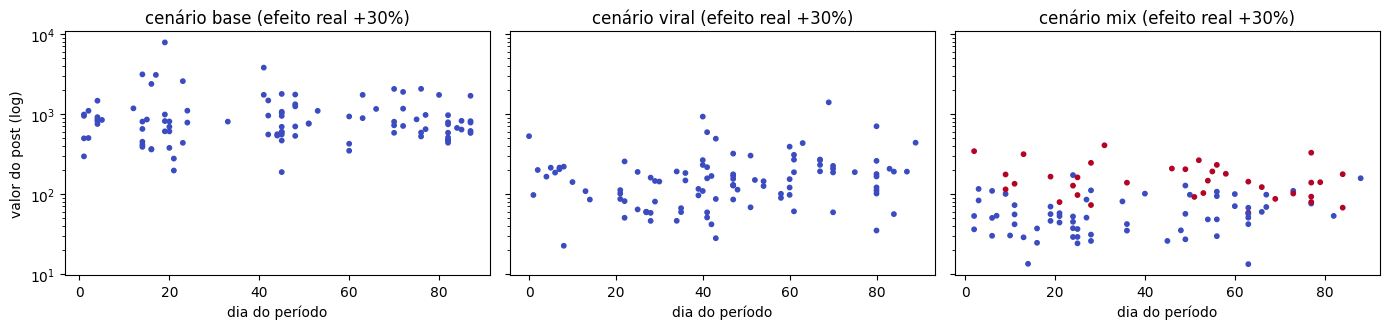

In [2]:
def gerar_perfil(rng, n, efeito, cenario):
    pesos = rng.gamma(0.6, size=PERIODO_DIAS)
    dias = np.sort(rng.choice(PERIODO_DIAS, size=n, p=pesos / pesos.sum()))
    t = dias / PERIODO_DIAS
    sigma, p_viral, mult_viral = 0.5, 0.01, 5
    if cenario == "viral":
        sigma, p_viral, mult_viral = 0.6, 0.04, 8
    nivel = rng.lognormal(mean=np.log(200), sigma=0.8)
    formato = np.zeros(n, dtype=int)
    if cenario == "mix":
        formato = (rng.random(n) < 0.2 + 0.4 * t).astype(int)
    log_y = (
        np.log(nivel)
        + np.log1p(efeito) * t
        + 1.1 * formato
        + rng.normal(0, sigma, n)
        + (rng.random(n) < p_viral) * np.log(mult_viral)
    )
    return pd.DataFrame({"dia": dias, "t": t, "formato": formato, "y": np.exp(log_y)})


rng_demo = np.random.default_rng(SEED)
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for ax, cen in zip(eixos, CENARIOS):
    d = gerar_perfil(rng_demo, 100, 0.30, cen)
    ax.scatter(d["dia"], d["y"], s=10, c=d["formato"], cmap="coolwarm")
    ax.set_yscale("log")
    ax.set_title(f"cenário {cen} (efeito real +30%)")
    ax.set_xlabel("dia do período")
eixos[0].set_ylabel("valor do post (log)")
plt.tight_layout()
plt.show()

## 5. Métodos comparados

Todos trabalham no **log do valor** (variação relativa, robusta à escala do perfil) e devolvem a variação no período com
intervalo de confiança de 95%, exceto o CUSUM, que só devolve o estado.

| Método | Ideia |
|---|---|
| `ols` | Regressão linear de log(valor) no tempo. |
| `theil_sen` | Inclinação mediana dos pares de pontos; robusta a outliers. |
| `ols_controles` | OLS com o formato como controle (o que a regressão da ADR 0019 já faz). |
| `arima_semanal` | ARIMA(0,1,1) com deriva sobre a média semanal do log (série regular). |
| `eb_hierarquico` | *Shrinkage* empírico-Bayes entre os 26 perfis, sobre as inclinações do OLS com controles (aproxima o modelo bayesiano hierárquico sem MCMC). |
| `cusum` | Detecção de mudança por soma acumulada, com limiar `h` calibrado por tamanho de série para ~5% de falso alarme em série sem variação. Não projeta magnitude nem tem IC. |

In [3]:
def _ols_fit(df, controles=False):
    cols = [np.ones(len(df)), df["t"].to_numpy()]
    if controles and df["formato"].nunique() > 1:
        cols.append(df["formato"].to_numpy())
    X = np.column_stack(cols)
    r = sm.OLS(np.log(df["y"].to_numpy()), X).fit()
    return r.params[1], r.bse[1], r


def m_ols(df):
    b, se, r = _ols_fit(df)
    lo, hi = r.conf_int(alpha=1 - NIVEL_CONF)[1]
    return b, lo, hi


def m_ols_controles(df):
    b, se, r = _ols_fit(df, controles=True)
    lo, hi = r.conf_int(alpha=1 - NIVEL_CONF)[1]
    return b, lo, hi


def m_theil_sen(df):
    b, _, lo, hi = stats.theilslopes(np.log(df["y"].to_numpy()), df["t"].to_numpy(), alpha=NIVEL_CONF)
    return b, lo, hi


def m_arima(df):
    sem = (df["dia"] // 7).to_numpy()
    serie = pd.Series(np.log(df["y"].to_numpy())).groupby(sem).mean()
    serie = serie.reindex(range(int(serie.index.min()), int(serie.index.max()) + 1)).interpolate()
    if len(serie) < 6:
        return None
    r = ARIMA(serie.to_numpy(), order=(0, 1, 1), trend="t").fit()
    i = r.param_names.index("x1")
    por_periodo = PERIODO_DIAS / 7
    lo, hi = r.conf_int(alpha=1 - NIVEL_CONF)[i]
    return r.params[i] * por_periodo, lo * por_periodo, hi * por_periodo


def _cusum_max(df, k=0.5):
    y = np.log(df["y"].to_numpy())
    base = y[: max(3, int(0.3 * len(y)))]
    sigma = 1.4826 * np.median(np.abs(y - np.median(y))) or 1.0
    z = (y - np.median(base)) / sigma
    s_up = s_dn = max_up = max_dn = 0.0
    for v in z:
        s_up = max(0.0, s_up + v - k)
        s_dn = max(0.0, s_dn - v - k)
        max_up, max_dn = max(max_up, s_up), max(max_dn, s_dn)
    return max_up, max_dn


H_CUSUM = {}


def calibrar_h_cusum(n, rng, reps=400):
    # limiar que dá ~5% de falso alarme em série sem variação (cenário base), por tamanho de série
    maximos = [max(_cusum_max(gerar_perfil(rng, n, 0.0, "base"))) for _ in range(reps)]
    return float(np.quantile(maximos, 0.95))


def m_cusum(df):
    max_up, max_dn = _cusum_max(df)
    h = H_CUSUM.get(len(df), 4.0)
    if max(max_up, max_dn) <= h:
        return "Estável"
    return "Subindo" if max_up >= max_dn else "Caindo"


def por_perfil(fn):
    def aplicar(dfs):
        saida = []
        for df in dfs:
            try:
                saida.append(fn(df))
            except Exception:
                saida.append(None)
        return saida
    return aplicar


def eb_hierarquico(dfs):
    # normal-normal: b_i ~ N(theta_i, se_i^2), theta_i ~ N(mu, tau^2); tau^2 por DerSimonian-Laird
    ajustes = []
    for df in dfs:
        if len(df) < MIN_PUBLICACOES:
            ajustes.append(None)
            continue
        b, se, _ = _ols_fit(df, controles=True)
        ajustes.append((b, se))
    validos = [a for a in ajustes if a is not None]
    if len(validos) < 3:
        return [None] * len(dfs)
    b = np.array([a[0] for a in validos])
    v = np.array([a[1] ** 2 for a in validos])
    w = 1 / v
    mu_fixo = np.sum(w * b) / np.sum(w)
    q = np.sum(w * (b - mu_fixo) ** 2)
    c = np.sum(w) - np.sum(w**2) / np.sum(w)
    tau2 = max(0.0, (q - (len(b) - 1)) / c)
    w_re = 1 / (v + tau2)
    mu = np.sum(w_re * b) / np.sum(w_re)
    z = stats.norm.ppf(0.5 + NIVEL_CONF / 2)
    saida = []
    for a in ajustes:
        if a is None:
            saida.append(None)
            continue
        bi, sei = a
        fator = tau2 / (tau2 + sei**2)
        media = mu + fator * (bi - mu)
        dp = np.sqrt(fator) * sei
        saida.append((media, media - z * dp, media + z * dp))
    return saida


METODOS = {
    "ols": por_perfil(m_ols),
    "theil_sen": por_perfil(m_theil_sen),
    "ols_controles": por_perfil(m_ols_controles),
    "arima_semanal": por_perfil(m_arima),
    "eb_hierarquico": eb_hierarquico,
    "cusum": por_perfil(m_cusum),
}


def estado_do_contrato(df, res):
    if len(df) < MIN_PUBLICACOES or df["dia"].nunique() < MIN_DIAS_COM_PUBLICACAO or res is None:
        return "Dados insuficientes"
    if isinstance(res, str):
        return res
    est, lo, hi = np.expm1(res[0]), np.expm1(res[1]), np.expm1(res[2])
    if lo > 0 and est >= MIN_EFEITO:
        return "Subindo"
    if hi < 0 and est <= -MIN_EFEITO:
        return "Caindo"
    return "Estável"

# Sanidade: ARIMA recupera deriva conhecida em série sem ruído?
rng_s = np.random.default_rng(1)
d = gerar_perfil(rng_s, 250, 0.30, "base")
d["y"] = np.exp(np.log(200) + np.log1p(0.30) * d["t"])
print("verdade log(1.3) =", round(np.log(1.3), 3), "| ols", round(m_ols(d)[0], 3), "| arima", round(m_arima(d)[0], 3))
assert abs(m_arima(d)[0] - np.log(1.3)) < 0.03 and abs(m_ols(d)[0] - np.log(1.3)) < 0.03

verdade log(1.3) = 0.262 | ols 0.262 | arima 0.259


## 6. Experimento

Cada repetição simula uma Coleta com 26 governadores; o efeito verdadeiro de cada um é sorteado (50% sem variação, 25% de
queda de 15% ou 30%, 25% de alta de 15% ou 30%). Variamos o número de publicações por perfil (12, 40, 100, 250) e o cenário.

Métricas por método:

- **falso alarme**: perfil sem variação real classificado como Subindo ou Caindo;
- **poder**: perfil com variação real classificado no estado certo;
- **direção errada**: Subindo quando é Caindo ou o inverso (o erro mais grave para o analista);
- **cobertura do IC**: fração dos intervalos que contêm a variação verdadeira (esperado: ~95%);
- **erro de magnitude**: erro absoluto médio da variação estimada, em pontos percentuais.

In [4]:
def rodar(n_posts, cenario, reps, rng):
    linhas = []
    for _ in range(reps):
        efeitos = rng.choice(EFEITOS, size=N_GOVERNADORES, p=PROBS)
        dfs = [gerar_perfil(rng, n_posts, e, cenario) for e in efeitos]
        for nome, metodo in METODOS.items():
            res = metodo(dfs)
            for e, df, r in zip(efeitos, dfs, res):
                estado = estado_do_contrato(df, r)
                tem_ic = isinstance(r, tuple) and estado != "Dados insuficientes"
                linhas.append(
                    {
                        "n_posts": n_posts,
                        "cenario": cenario,
                        "metodo": nome,
                        "efeito_real": e,
                        "estado": estado,
                        "est": np.expm1(r[0]) if tem_ic else np.nan,
                        "cobre": (r[1] <= np.log1p(e) <= r[2]) if tem_ic else np.nan,
                    }
                )
    return pd.DataFrame(linhas)


rng_cal = np.random.default_rng(SEED + 7)
for n in N_POSTS:
    H_CUSUM[n] = calibrar_h_cusum(n, rng_cal)
print("h do CUSUM calibrado:", {k: round(v, 1) for k, v in H_CUSUM.items()})

rng = np.random.default_rng(SEED)
inicio = time.time()
frames = []
for cen in CENARIOS:
    for n in N_POSTS:
        frames.append(rodar(n, cen, REPS, rng))
    print(cen, "ok", round(time.time() - inicio), "s")
sim = pd.concat(frames, ignore_index=True)
sim["verdade"] = np.select([sim.efeito_real > 0, sim.efeito_real < 0], ["Subindo", "Caindo"], "Estável")
print(len(sim), "linhas")

h do CUSUM calibrado: {12: 11.4, 40: 10.5, 100: 11.6, 250: 9.8}


base ok 95 s


viral ok 187 s


mix ok 280 s
37440 linhas


In [5]:
def resumo(d):
    est0 = d[d.verdade == "Estável"]
    mov = d[d.verdade != "Estável"]
    oposto = {"Subindo": "Caindo", "Caindo": "Subindo"}
    return pd.Series(
        {
            "falso_alarme": est0.estado.isin(["Subindo", "Caindo"]).mean(),
            "poder": (mov.estado == mov.verdade).mean(),
            "direcao_errada": (mov.estado == mov.verdade.map(oposto)).mean(),
            "insuficiente": (d.estado == "Dados insuficientes").mean(),
            "cobertura_ic": d.cobre.dropna().astype(float).mean(),
            "erro_magnitude_pp": ((d.est - d.efeito_real).abs().mean() * 100),
        }
    )


geral = sim.groupby("metodo").apply(resumo)
print("Visão geral (todos os cenários e tamanhos):")
geral

Visão geral (todos os cenários e tamanhos):


,falso_alarme,poder,direcao_errada,insuficiente,cobertura_ic,erro_magnitude_pp
metodo,,,,,,
arima_semanal,0.075,0.095,0.012,0.003,0.927,72.156
cusum,0.122,0.135,0.022,0.003,NaN,NaN
eb_hierarquico,0.110,0.145,0.049,0.003,0.779,12.974
ols,0.146,0.200,0.026,0.003,0.848,48.559
ols_controles,0.043,0.183,0.007,0.003,0.953,29.969
theil_sen,0.146,0.201,0.025,0.003,0.849,52.271


In [6]:
por_cenario = sim.groupby(["cenario", "metodo"]).apply(resumo)
por_cenario[["falso_alarme", "poder", "direcao_errada", "cobertura_ic"]]

falso_alarme  poder  direcao_errada  cobertura_ic
cenario metodo                                                           
base    arima_semanal          0.043  0.080           0.008         0.962
        cusum                  0.056  0.100           0.009           NaN
        eb_hierarquico         0.037  0.123           0.014         0.835
        ols                    0.050  0.196           0.006         0.948
        ols_controles          0.050  0.196           0.006         0.948
        theil_sen              0.049  0.188           0.003         0.954
mix     arima_semanal          0.150  0.142           0.025         0.846
        cusum                  0.190  0.179           0.033           NaN
        eb_hierarquico         0.124  0.166           0.056         0.774
        ols                    0.342  0.267           0.066         0.641
        ols_controles          0.044  0.214           0.007         0.955
        theil_sen              0.339  0.261           0.066         0.641
viral   arima_semanal          0.027  0.067           0.005         0.973
        cusum                  0.116  0.128           0.023           NaN
        eb_hierarquico         0.170  0.147           0.076         0.728
        ols                    0.033  0.141           0.008         0.954
        ols_controles          0.033  0.141           0.008         0.954
        theil_sen              0.037  0.158           0.009         0.952

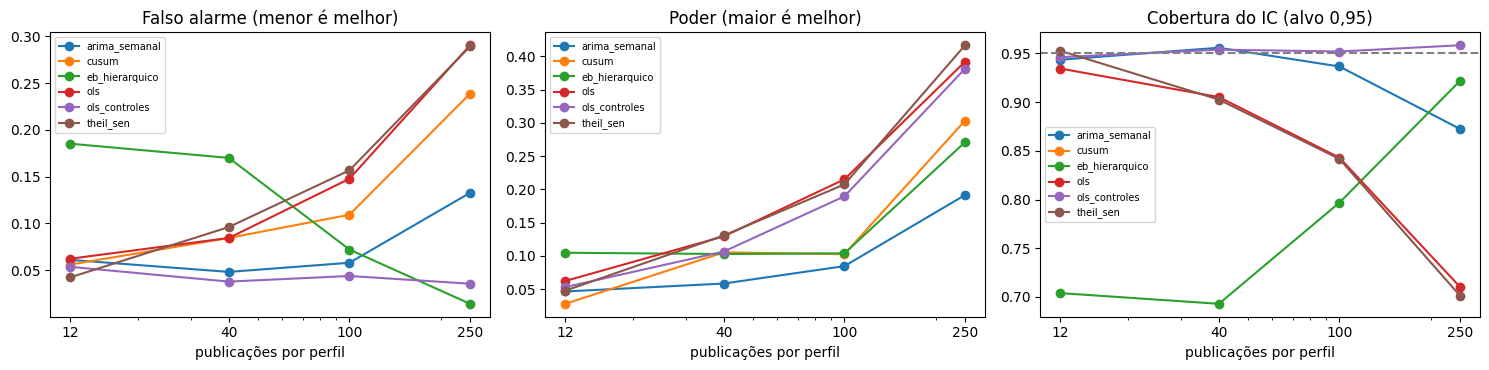

falso_alarme  poder  direcao_errada  insuficiente
n_posts metodo                                                           
12      arima_semanal          0.061  0.046           0.015         0.013
        cusum                  0.056  0.028           0.019         0.013
        eb_hierarquico         0.185  0.105           0.086         0.013
        ols                    0.062  0.062           0.016         0.013
        ols_controles          0.053  0.053           0.013         0.013
        theil_sen              0.042  0.048           0.017         0.013
40      arima_semanal          0.048  0.058           0.008         0.000
        cusum                  0.084  0.105           0.013         0.000
        eb_hierarquico         0.170  0.103           0.087         0.000
        ols                    0.084  0.129           0.018         0.000
        ols_controles          0.038  0.106           0.010         0.000
        theil_sen              0.096  0.131           0.018         0.000
100     arima_semanal          0.058  0.085           0.013         0.000
        cusum                  0.109  0.102           0.024         0.000
        eb_hierarquico         0.072  0.104           0.022         0.000
        ols                    0.148  0.215           0.035         0.000
        ols_controles          0.044  0.190           0.005         0.000
        theil_sen              0.157  0.207           0.032         0.000
250     arima_semanal          0.133  0.191           0.014         0.000
        cusum                  0.239  0.303           0.031         0.000
        eb_hierarquico         0.014  0.271           0.000         0.000
        ols                    0.290  0.392           0.035         0.000
        ols_controles          0.035  0.382           0.000         0.000
        theil_sen              0.289  0.417           0.034         0.000

In [7]:
por_n = sim.groupby(["n_posts", "metodo"]).apply(resumo)
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, titulo in zip(
    eixos, ["falso_alarme", "poder", "cobertura_ic"], ["Falso alarme (menor é melhor)", "Poder (maior é melhor)", "Cobertura do IC (alvo 0,95)"]
):
    p = por_n[col].unstack("metodo")
    p.plot(ax=ax, marker="o")
    ax.set_title(titulo)
    ax.set_xlabel("publicações por perfil")
    ax.set_xscale("log")
    ax.set_xticks(N_POSTS)
    ax.set_xticklabels(N_POSTS)
    if col == "cobertura_ic":
        ax.axhline(0.95, color="gray", ls="--")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
por_n[["falso_alarme", "poder", "direcao_errada", "insuficiente"]].round(3)

## 7. Visão "Todos": como agregar o conjunto?

Decisão já tomada: na visão "Todos" a tendência é a do **conjunto**. Aqui medimos a armadilha apontada na conversa: um perfil
que publica muito e com nível alto dominando a série agregada.

Cenário: 25 governadores **sem variação** e 1 governador com nível ×10 e **queda de 30%**. A verdade do conjunto (média dos
efeitos por perfil) é praticamente estável (~−1%). Comparamos três formas de agregar, todas com Theil–Sen para isolar o efeito
da agregação:

- **soma bruta**: soma dos valores por dia (o perfil grande domina);
- **normalizada**: cada valor dividido pela média do próprio perfil, depois todos juntos (cada perfil pesa igual);
- **mediana das tendências**: mediana das variações individuais, com IC por *bootstrap* de perfis.

In [8]:
def agregar(dfs, modo, rng):
    if modo == "soma_bruta":
        d = pd.concat(dfs).groupby("dia", as_index=False).agg(y=("y", "sum"))
        d["t"] = d["dia"] / PERIODO_DIAS
        return m_theil_sen(d)
    if modo == "normalizada":
        d = pd.concat([x.assign(y=x["y"] / x["y"].mean()) for x in dfs])
        return m_theil_sen(d)
    ests = np.array([m_theil_sen(x)[0] for x in dfs])
    boots = [np.median(rng.choice(ests, size=len(ests))) for _ in range(300)]
    lo, hi = np.quantile(boots, [(1 - NIVEL_CONF) / 2, 1 - (1 - NIVEL_CONF) / 2])
    return np.median(ests), lo, hi


rng_t = np.random.default_rng(SEED + 1)
estados = {m: [] for m in ["soma_bruta", "normalizada", "mediana_tendencias"]}
for _ in range(100):
    dfs = [gerar_perfil(rng_t, 100, 0.0, "base") for _ in range(25)]
    grande = gerar_perfil(rng_t, 100, -0.30, "base")
    grande["y"] = grande["y"] * 10
    dfs.append(grande)
    for modo, chave in [("soma_bruta", "soma_bruta"), ("normalizada", "normalizada"), ("mediana", "mediana_tendencias")]:
        estados[chave].append(estado_do_contrato(dfs[0], agregar(dfs, modo, rng_t)))
pd.DataFrame({m: pd.Series(v).value_counts(normalize=True) for m, v in estados.items()}).fillna(0).round(2)

,soma_bruta,normalizada,mediana_tendencias
Caindo,0.030,0.130,0.060
Estável,0.970,0.860,0.910
Subindo,0.000,0.010,0.030


## 8. Teste de fumaça com o dado real do piloto

**Não é avaliação.** O piloto tem ~17 reels por perfil espalhados em 21 meses (teto de 30 itens). Serve só para verificar que o
código roda sobre as colunas reais (`data_hora`, `Total de Engajamento`) e mostrar a distribuição de estados que o contrato daria.
A leitura é direta da Silver local, sem `DeltaRepository`, por ser exploratória e fora do pipeline.

In [9]:
def achar_silver():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "silver" / "reels_clean").exists():
            return p / "data" / "silver"
    return None


silver = achar_silver()
if silver is None:
    print("Silver local não encontrada; célula ignorada.")
else:
    from deltalake import DeltaTable

    reels = DeltaTable(str(silver / "reels_clean")).to_pandas()
    chave = next(c for c in ("ownerUsername", "inputUrl") if c in reels.columns)
    reels["_dt"] = pd.to_datetime(reels["data_hora"], errors="coerce", utc=True)
    reels = reels.dropna(subset=["_dt"])
    saida = []
    for perfil, g in reels.groupby(chave):
        dias = (g["_dt"] - g["_dt"].min()).dt.days.to_numpy()
        span = max(int(dias.max()), 1)
        d = pd.DataFrame({"dia": dias, "t": dias / 90, "formato": 0, "y": g["Total de Engajamento"].clip(lower=1).to_numpy()})
        for nome, fn in [("ols", m_ols), ("theil_sen", m_theil_sen)]:
            try:
                r = fn(d)
            except Exception:
                r = None
            saida.append({"perfil": perfil, "metodo": nome, "pubs": len(d), "span_dias": span, "estado": estado_do_contrato(d, r)})
    real = pd.DataFrame(saida)
    print(real.pivot_table(index="metodo", columns="estado", values="perfil", aggfunc="count", fill_value=0))

estado     Caindo  Dados insuficientes  Estável
metodo                                         
ols             1                   24        0
theil_sen       0                   24        1


## 9. Leitura dos resultados (fase 1, preliminar)

20 repetições × 26 perfis por célula (520 séries): o erro de Monte Carlo é de alguns pontos percentuais; diferenças menores que
isso não são conclusivas.

**O que a simulação sustenta**

- **OLS com o formato como controle é o melhor candidato.** Falso alarme 4,3%, direção errada 0,7%, cobertura do IC 95,3% (a
  nominal) em todos os cenários. Nos cenários `base` e `viral` é igual ao OLS simples.
- **Controlar o mix de formato pesa mais do que usar estimador robusto.** No cenário `mix` (sem variação real), OLS e Theil–Sen
  dão ~34% de falso alarme e cobertura de 64%; com o controle, 4,4% e 95,5%. Theil–Sen ≈ OLS nos demais cenários, inclusive no
  `viral`.
- **ARIMA semanal** é bem calibrado em `base`/`viral` (cobertura 96–97%), mas tem menos poder e erra no `mix`. Não compensa
  frente ao OLS com controle.
- **CUSUM calibrado** (limiar `h` por tamanho de série) fica com ~12% de falso alarme, piora com séries longas e no `mix`, e não
  dá magnitude nem intervalo. Serve, no máximo, como alerta, não como a seta de Tendência.
- **Hierárquico (empírico-Bayes sobre OLS com controle)** tem cobertura de 78%, abaixo do nominal, e mais direção errada com
  poucas publicações (8,6% com 12 posts). Com 250 posts, falso alarme 1,4% e poder 27%. Não há ganho claro com 26 perfis; a
  versão bayesiana completa (MCMC) não foi testada.

**O achado que muda o produto: o poder é baixo.** Mesmo o melhor método detecta só ~19% das variações reais de ±15%/±30% com
100 publicações (38% com 250). Com ruído do tamanho do assumido, a maioria das setas será **Estável**. Isso é o contrato
funcionando (não inventa seta), mas "Estável" no dashboard vai significar "sem evidência suficiente", não "nada mudou". O rótulo
e o texto de apoio precisam dizer isso. Poder por tamanho de efeito não foi decomposto aqui.

**Visão "Todos"** (100 repetições, verdade do conjunto ≈ −1%): a hipótese de que o perfil grande domina a soma bruta **não se
confirmou** nesse nível de ruído (3% de falso alarme). A agregação normalizada teve o maior falso alarme (13% Caindo) e a
mediana das tendências 9%. Evidência insuficiente para escolher; refazer com dominância mais forte e mais repetições.

**Teste de fumaça com dado real:** 24 de 25 perfis ficaram "Dados insuficientes" (poucos dias distintos com reel no piloto). O
código roda nas colunas reais; nada a concluir sobre o método.

## 10. Limites e próximos passos

- Premissas do gerador (ruído log-normal homocedástico, tendência log-linear, efeito constante) podem não valer no dado real.
- Faltam: poder por tamanho de efeito, sensibilidade ao `MIN_EFEITO` e aos mínimos de publicação, tendência não linear (campanhas,
  sazonalidade), indicadores que são proporção (NSM, % positivo), onde o modelo log-linear não se aplica diretamente.
- **Fase 2:** *backtest* com a Coleta de 90 dias (#256): estimar numa janela, testar na seguinte. Só então fixar método e
  limiares e atualizar a ADR 0040.